# Gaussian mixture models on the CMU keystroke benchmark

**Goal.** Train a Gaussian mixture model (GMM) as a keystroke anomaly detector and see how it
compares with the 14 detectors of the CMU benchmark
([Killourhy & Maxion, DSN 2009](https://roymaxion.github.io/projects/keystroke-benchmark/benchmark-data-set.html)).

**Data.** 51 subjects each typed the password `.tie5Roanl` 400 times over 8 sessions (50 per session).
Each typing is one data point with 31 timings: 11 hold times (H), 10 keydown-keydown (DD) and
10 keyup-keydown (UD) latencies.

**Protocol (identical to the benchmark).** For each subject in turn:
* train on the subject's first 200 typings (sessions 1-4);
* score the subject's last 200 typings (genuine) and the first 5 typings of each of the other 50 subjects (250 impostor typings);
* compute the equal-error rate (EER), the error rate at the threshold where false-accept and false-reject rates are equal.

The detector's score is the mean EER (and its SD) over the 51 subjects.

**How a GMM becomes a detector.** For each subject we fit a density $p(x \mid \text{user})$ to their
training typings. A new typing's score is its log-likelihood: the higher, the more genuine.
The number of components $K \in \{1, 2, 3\}$ is chosen per subject by BIC.

**Where this notebook differs from the benchmark (as the benchmark page asks us to state).**
1. *Hyperparameter tuning.* The GMM's covariance regularization is chosen on a validation split carved out
   of the training data (fit on typings 1-160, validate on 161-200; impostors from the other subjects'
   typings 6-10). The test typings are never used for any choice. The published detectors were not tuned this way.
2. *Feature sets.* The benchmark table uses the 31 raw features. We also report two variants:
   * **raw21**: drops the 10 UD features. They are exactly DD − H, so raw21 carries the same information.
   * **log21**: log-transformed raw21, where timings are closer to Gaussian.

   We re-run the four published distance detectors on each feature set, so that every comparison
   is on equal footing.

**Notebook layout.**
setup → saving helpers → data → data figures → models → tuning → training & test → model figures → evaluation → save.

## 1. Setup

Imports and reproducibility. Run inside the `keystroke-gmm` conda env (kernel *Python (keystroke-gmm)*).
All model code lives in `src/`; this notebook only orchestrates it.

In [1]:
import os, sys, json, time
from pathlib import Path
os.environ.setdefault("OMP_NUM_THREADS", "1")   # avoids a known sklearn KMeans/MKL memory-leak warning on Windows

# Make `src` importable whether the notebook runs from the repo root or from notebooks/.
REPO = Path.cwd().resolve()
if REPO.name == "notebooks":
    REPO = REPO.parent
sys.path.insert(0, str(REPO))

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

from src import utils as U          # data loading, feature sets, splits, EER, statistics
from src import models as M         # detectors and density models
from src import plots as P          # figure builders (they never save)
from src import experiments as E    # published benchmark table, comparison tables, diagnostics
from src.evaluation import ModelSpec, evaluate, grid, tune
from src.saving import Saver

SEED = 0                              # every random choice below derives from this seed
np.random.seed(SEED)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)
T0 = time.time()

## 2. Saving helpers

This is the only cell that sets up saving. Every experiment below is a *run* with its own folder,
`outputs/<NAME><NNN>_<timestamp>/`, which is never overwritten.

* `start_run(name, config)` creates the folder and writes `config.json` and `env.json` immediately, **before training**.
* `run.capture()` copies everything printed inside it, plus any warnings, into the run's `log.txt`.
* `run.add_figure(...)` and `run.set_results(...)` keep figures, metrics, scores and fitted models in memory.
* `save_all()` (the last cell) writes them out with `save_model`, `save_figure` and `save_run`,
  and appends one row per run to `outputs/runs_index.csv`.

In [2]:
saver = Saver(REPO, REPO / "outputs")
start_run, save_run, save_model, save_figure, save_all = (
    saver.start_run, saver.save_run, saver.save_model, saver.save_figure, saver.save_all)
print("outputs ->", saver.out)

outputs -> C:\classProjects\keystroke-gmm\CAP5610-Keystroke-Analysis\outputs


## 3. Data

`load_data` checks the file's MD5 against the benchmark's published checksum, sorts typings
chronologically per subject, and adds `typing` = 1..400.

The check below confirms two facts the analysis relies on:
1. every UD feature equals DD − H, up to the 4-decimal rounding of the file;
2. so the 31 features have rank 21, and a full covariance matrix on raw31 is singular.

In [3]:
df = U.load_data()   # raises with download instructions if data/DSL-StrongPasswordData.csv is missing
print(df.shape, "| subjects:", df.subject.nunique(), "| typings per subject:", df.groupby("subject").size().unique())

# Three feature sets used throughout: name -> (matrix, column names)
FEATURE_SETS = {
    "raw31": "31 raw timings: the benchmark's features",
    "raw21": "11 H + 10 DD raw timings: same information, redundant UD removed",
    "log21": "log of the 11 H + 10 DD timings",
}
FEATS = {fs: U.make_features(df, fs) for fs in FEATURE_SETS}

# Check 1: UD = DD - H for every key pair. Columns come in the order H.a, DD.a.b, UD.a.b, H.b, ...
# (key names such as "Shift.r" contain dots, so we pair columns by position, not by name)
cols = U.timing_columns(df)
ud_err = max(np.abs(df[cols[i]] - (df[cols[i - 1]] - df[cols[i - 2]])).max()
             for i, c in enumerate(cols) if c.startswith("UD."))
# Check 2: rank of one subject's 200 training typings
Xtr0 = FEATS["raw31"][0][U.rows(0, 1, U.TRAIN_END)]
print(f"max |UD - (DD - H)| = {ud_err:.1e}   (4-decimal rounding -> exact up to 1e-4)")
print("rank of raw31 training matrix (subject 0):", np.linalg.matrix_rank(Xtr0, tol=1e-6), "of", Xtr0.shape[1])
display(pd.DataFrame({"features": list(FEATURE_SETS.values()), "dim": [FEATS[f][0].shape[1] for f in FEATURE_SETS]},
                     index=list(FEATURE_SETS)))

(20400, 35) | subjects: 51 | typings per subject: [400]
max |UD - (DD - H)| = 8.9e-16   (4-decimal rounding -> exact up to 1e-4)
rank of raw31 training matrix (subject 0): 21 of 31


,features,dim
raw31,31 raw timings: the benchmark's features,31
raw21,"11 H + 10 DD raw timings: same information, re...",21
log21,log of the 11 H + 10 DD timings,21


### 3b. Data figures

* **Raw vs log histograms.** Raw timings are right-skewed with long tails. After a log transform
  they are much closer to Gaussian, which matters for Gaussian-based models.
* **Within- vs between-user spread.** For each feature, compare how much one subject varies
  (within-user SD) with how much subjects differ from each other (SD of the subject means).
  Features with a large between/within ratio carry most of the identity information.

[run] outputs\bench_data_overview001_20261126-101340
mean skewness of the features: {'raw21': 6.78, 'log21': 0.06}


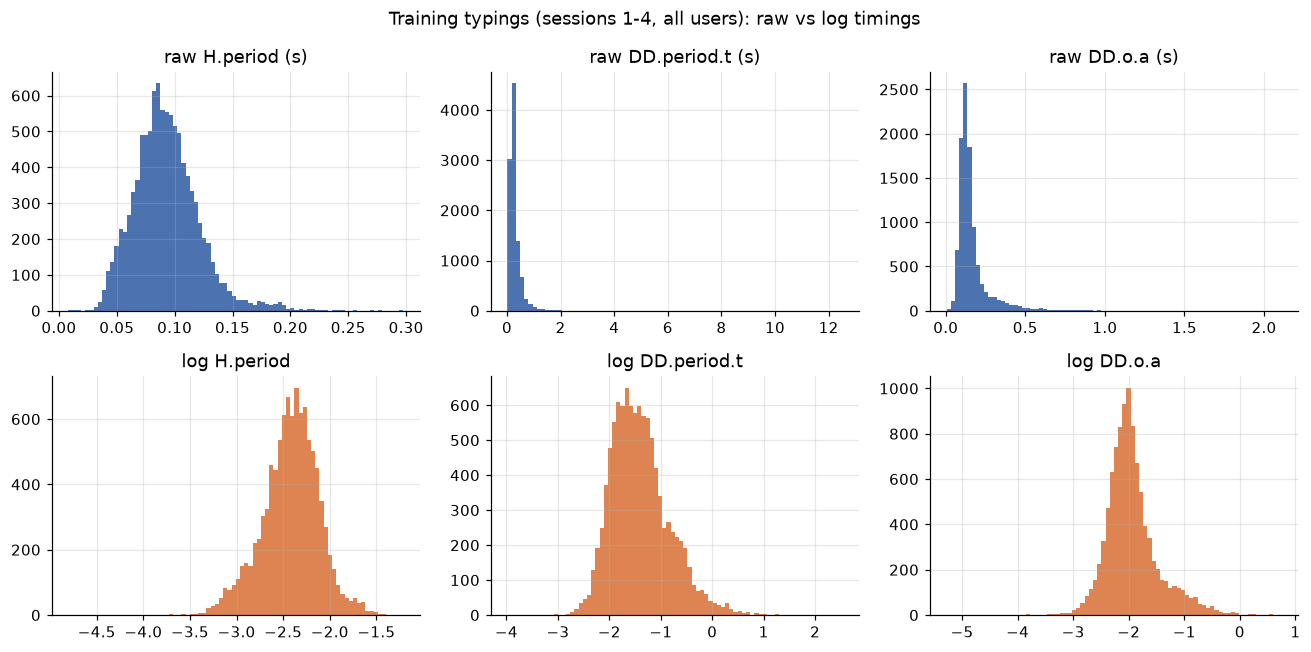

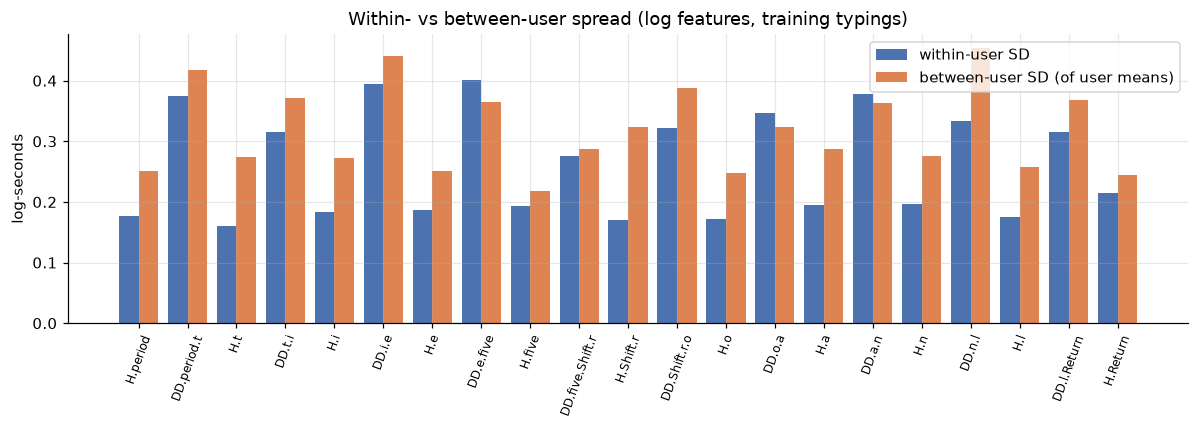

In [4]:
run_data = start_run("bench_data_overview", {
    "model": "none (descriptive figures)", "features": "raw21 vs log21", "protocol": "descriptive",
    "split_short": "train(1-200)", "split": "training typings 1-200 of all subjects",
    "n_train": 200, "sampling": "first", "seed": SEED})
with run_data.capture():
    tr = U.rows(np.arange(U.N_USERS), 1, U.TRAIN_END)          # all training rows, all subjects
    skew = {fs: float(pd.DataFrame(FEATS[fs][0][tr]).skew().mean()) for fs in ("raw21", "log21")}
    print("mean skewness of the features:", {k: round(v, 2) for k, v in skew.items()})
run_data.add_figure(P.raw_vs_log(FEATS["raw21"][0], FEATS["log21"][0], FEATS["raw21"][1]), "raw_vs_log_histograms")
run_data.add_figure(P.within_between(FEATS["log21"][0], FEATS["log21"][1]), "within_vs_between_user_spread")
run_data.set_results(metrics={"mean_skewness": skew})

## 4. Models

| model | what it is | hyperparameters |
|---|---|---|
| **GMM** | full-covariance Gaussian mixture on per-subject standardized features. $K$ = 1..3 by BIC ($K \le 2$ below 50 typings), 3 k-means initialisations | `reg_covar`, a ridge added to each component's covariance (tuned) |
| Gaussian full | a single full-covariance Gaussian: the $K=1$ control that shows whether extra components help | `reg`, ridge relative to the mean variance (tuned) |
| Euclidean, Manhattan, Mahalanobis, Scaled Manhattan | the benchmark's distance detectors (score = −distance to the training mean) | none |

The GMM's `reg_covar` is essential on raw31. There the covariance is singular (rank 21 of 31),
and the ridge is the only thing that keeps the likelihood finite.

In [5]:
# Tuned models: name -> (factory taking hyperparameters, validation grid)
TUNABLE = {
    "GMM": (lambda **p: ModelSpec("GMM", M.GMM, {"k_max": 3, "n_init": 3, **p}),
            grid(reg_covar=[1e-3, 3e-3, 1e-2, 3e-2])),
    "Gaussian full": (lambda **p: ModelSpec("Gaussian full", M.FullGaussian, p),
                      grid(reg=[1e-3, 1e-2, 3e-2, 1e-1, 3e-1])),
}
# Published distance detectors: no hyperparameters
DETECTORS = {"Euclidean": M.Euclidean, "Manhattan": M.Manhattan,
             "Mahalanobis": M.Mahalanobis, "Scaled Manhattan": M.ScaledManhattan}
pd.DataFrame([{"model": k, "grid": json.dumps(v[1])} for k, v in TUNABLE.items()]
             + [{"model": k, "grid": "-"} for k in DETECTORS])

,model,grid
0,GMM,"[{""reg_covar"": 0.001}, {""reg_covar"": 0.003}, {..."
1,Gaussian full,"[{""reg"": 0.001}, {""reg"": 0.01}, {""reg"": 0.03},..."
2,Euclidean,-
3,Manhattan,-
4,Mahalanobis,-
5,Scaled Manhattan,-


## 5. Hyperparameter tuning (validation only)

For every feature set and tuned model we try each grid point on the **validation split**:
* fit on typings 1-160;
* genuine validation typings 161-200;
* impostors = the other subjects' typings 6-10.

The test typings (subjects' sessions 5-8 and the impostors' typings 1-5) are not touched.
The point with the lowest mean validation EER wins. A run folder is created, with its `config.json`,
before tuning starts.

In [6]:
RUNS, TUNED = {}, {}
for fs, desc in FEATURE_SETS.items():
    Xf = FEATS[fs][0]
    for name, (make, g) in TUNABLE.items():
        run = start_run(f"bench_{name}_{fs}", {
            "model": name, "hyperparameter_grid": g, "selection": "lowest mean validation EER",
            "features": f"{fs}: {desc}", "protocol": "CMU benchmark (Killourhy & Maxion 2009)",
            "split_short": "val->test",
            "split": {"tuning": "fit 1-160, genuine 161-200, impostors = others' typings 6-10",
                      "test": "refit 1-200, genuine 201-400, impostors = others' typings 1-5 (250)"},
            "n_train": 200, "sampling": "first", "seed": SEED})
        with run.capture():
            print(f"--- {name} on {fs}")
            best, table = tune(Xf, make, g)            # validation only
            print("chosen:", best)
        RUNS[(name, fs)], TUNED[(name, fs)] = run, (best, table)

# Validation EER of every grid point, side by side
pd.concat({f"{n} | {fs}": t.set_index(list(TUNABLE[n][1][0]))["val_mean_eer"] for (n, fs), (_, t) in TUNED.items()}, axis=1)

[run] outputs\bench_GMM_raw31001_20261126-101340
--- GMM on raw31


  GMM(k_max=3, n_init=3, reg_covar=0.001)                      val EER 0.1249


  GMM(k_max=3, n_init=3, reg_covar=0.003)                      val EER 0.1249


  GMM(k_max=3, n_init=3, reg_covar=0.01)                       val EER 0.1247


  GMM(k_max=3, n_init=3, reg_covar=0.03)                       val EER 0.1246
chosen: {'reg_covar': 0.03}


[run] outputs\bench_Gaussian_full_raw31001_20261126-101345
--- Gaussian full on raw31
  Gaussian full(reg=0.001)                                     val EER 0.1257
  Gaussian full(reg=0.01)                                      val EER 0.1285
  Gaussian full(reg=0.03)                                      val EER 0.1334
  Gaussian full(reg=0.1)                                       val EER 0.1478
  Gaussian full(reg=0.3)                                       val EER 0.1596
chosen: {'reg': 0.001}


... (9 outputs left out)

  GMM(k_max=3, n_init=3, reg_covar=0.01)                       val EER 0.1019


  GMM(k_max=3, n_init=3, reg_covar=0.03)                       val EER 0.1012
chosen: {'reg_covar': 0.001}


[run] outputs\bench_Gaussian_full_log21001_20261126-101356
--- Gaussian full on log21
  Gaussian full(reg=0.001)                                     val EER 0.0997
  Gaussian full(reg=0.01)                                      val EER 0.0996
  Gaussian full(reg=0.03)                                      val EER 0.0996
  Gaussian full(reg=0.1)                                       val EER 0.1009
  Gaussian full(reg=0.3)                                       val EER 0.1040
chosen: {'reg': 0.01}


,GMM | raw31,Gaussian full | raw31,GMM | raw21,Gaussian full | raw21,GMM | log21,Gaussian full | log21
0.030,0.1246,0.1334,0.1218,0.1343,0.1012,0.0996
0.010,0.1247,0.1285,0.1233,0.1294,0.1019,0.0996
0.003,0.1249,NaN,0.1230,NaN,0.1017,NaN
0.001,0.1249,0.1257,0.1269,0.1259,0.0986,0.0997
0.100,NaN,0.1478,NaN,0.1498,NaN,0.1009
0.300,NaN,0.1596,NaN,0.1614,NaN,0.1040


## 6. Training and test (each model evaluated once)

Each tuned model is refit on all 200 training typings with its chosen hyperparameter and scored once on
the test typings. The four distance detectors have nothing to tune, so they go straight to test.

`evaluate` runs one model per subject and calls `utils.check_no_leak` before every fit, so a test typing
cannot be used for training by accident.

In [7]:
RESULTS = {}   # (model, feature set) -> EvalResult with per-user EER, scores and fitted models

# Tuned models: refit on 1-200 with the chosen setting, then one test evaluation.
for (name, fs), (best, table) in TUNED.items():
    run = RUNS[(name, fs)]
    with run.capture():
        res = evaluate(FEATS[fs][0], TUNABLE[name][0](**best), "test", keep_models=True)
        s = res.summary()
        print(f"{name:14s} {fs:6s} test EER {s['mean_eer']:.4f} (SD {s['sd_eer']:.4f})  "
              f"median test log-lik {s['test_ll_median']:.1f}")
    run.config["key_settings"] = best
    run.set_results(per_user=res.per_user, scores=res.scores, models=res.models, grid_table=table,
                    metrics={**s, "chosen": best, "val_mean_eer": float(table.val_mean_eer[0])},
                    best_config={"model": name, "features": fs, "chosen": best})
    RESULTS[(name, fs)] = res

# Distance detectors: nothing to tune.
for fs in FEATURE_SETS:
    for name, cls in DETECTORS.items():
        run = start_run(f"bench_{name}_{fs}", {
            "model": name, "features": fs, "protocol": "CMU benchmark", "split_short": "test",
            "n_train": 200, "sampling": "first", "seed": SEED})
        with run.capture():
            res = evaluate(FEATS[fs][0], ModelSpec(name, cls), "test", keep_models=True)
            print(f"{name:17s} {fs:6s} test EER {res.eers.mean():.4f}")
        run.set_results(per_user=res.per_user, metrics=res.summary(), scores=res.scores,
                        models=res.models, best_config={"model": name, "features": fs})
        RESULTS[(name, fs)] = res

GMM            raw31  test EER 0.1098 (SD 0.0643)  median test log-lik 65.6


Gaussian full  raw31  test EER 0.1106 (SD 0.0648)  median test log-lik 80.8


GMM            raw21  test EER 0.1045 (SD 0.0632)  median test log-lik 40.0


Gaussian full  raw21  test EER 0.1110 (SD 0.0647)  median test log-lik 38.7


GMM            log21  test EER 0.0978 (SD 0.0571)  median test log-lik -3.0


Gaussian full  log21  test EER 0.0974 (SD 0.0550)  median test log-lik -2.6


... (11 outputs left out)

Manhattan         log21  test EER 0.0998


[run] outputs\bench_Mahalanobis_log21001_20261126-101401


Mahalanobis       log21  test EER 0.0974


[run] outputs\bench_Scaled_Manhattan_log21001_20261126-101401
Scaled Manhattan  log21  test EER 0.0855


## 7. Model figures

* **Samples vs real typings.** For three subjects, typings drawn from the fitted GMM
  $p(x \mid \text{user})$ are compared with the subject's real training typings. Shown: marginal
  histograms of three features, and a scatter of two features. If the model fits, the samples
  overlap the real cloud.
* **Number of components.** How many subjects BIC gives 1, 2 or 3 components, per feature set.
* **DET curves.** Each curve is the trade-off between false accepts and false rejects as the threshold moves,
  averaged over subjects. Lower is better; the EER is where a curve crosses the diagonal.
* **Per-subject EER.** The GMM against Scaled Manhattan, the benchmark's best detector, for every subject.

[run] outputs\bench_figures001_20261126-101402


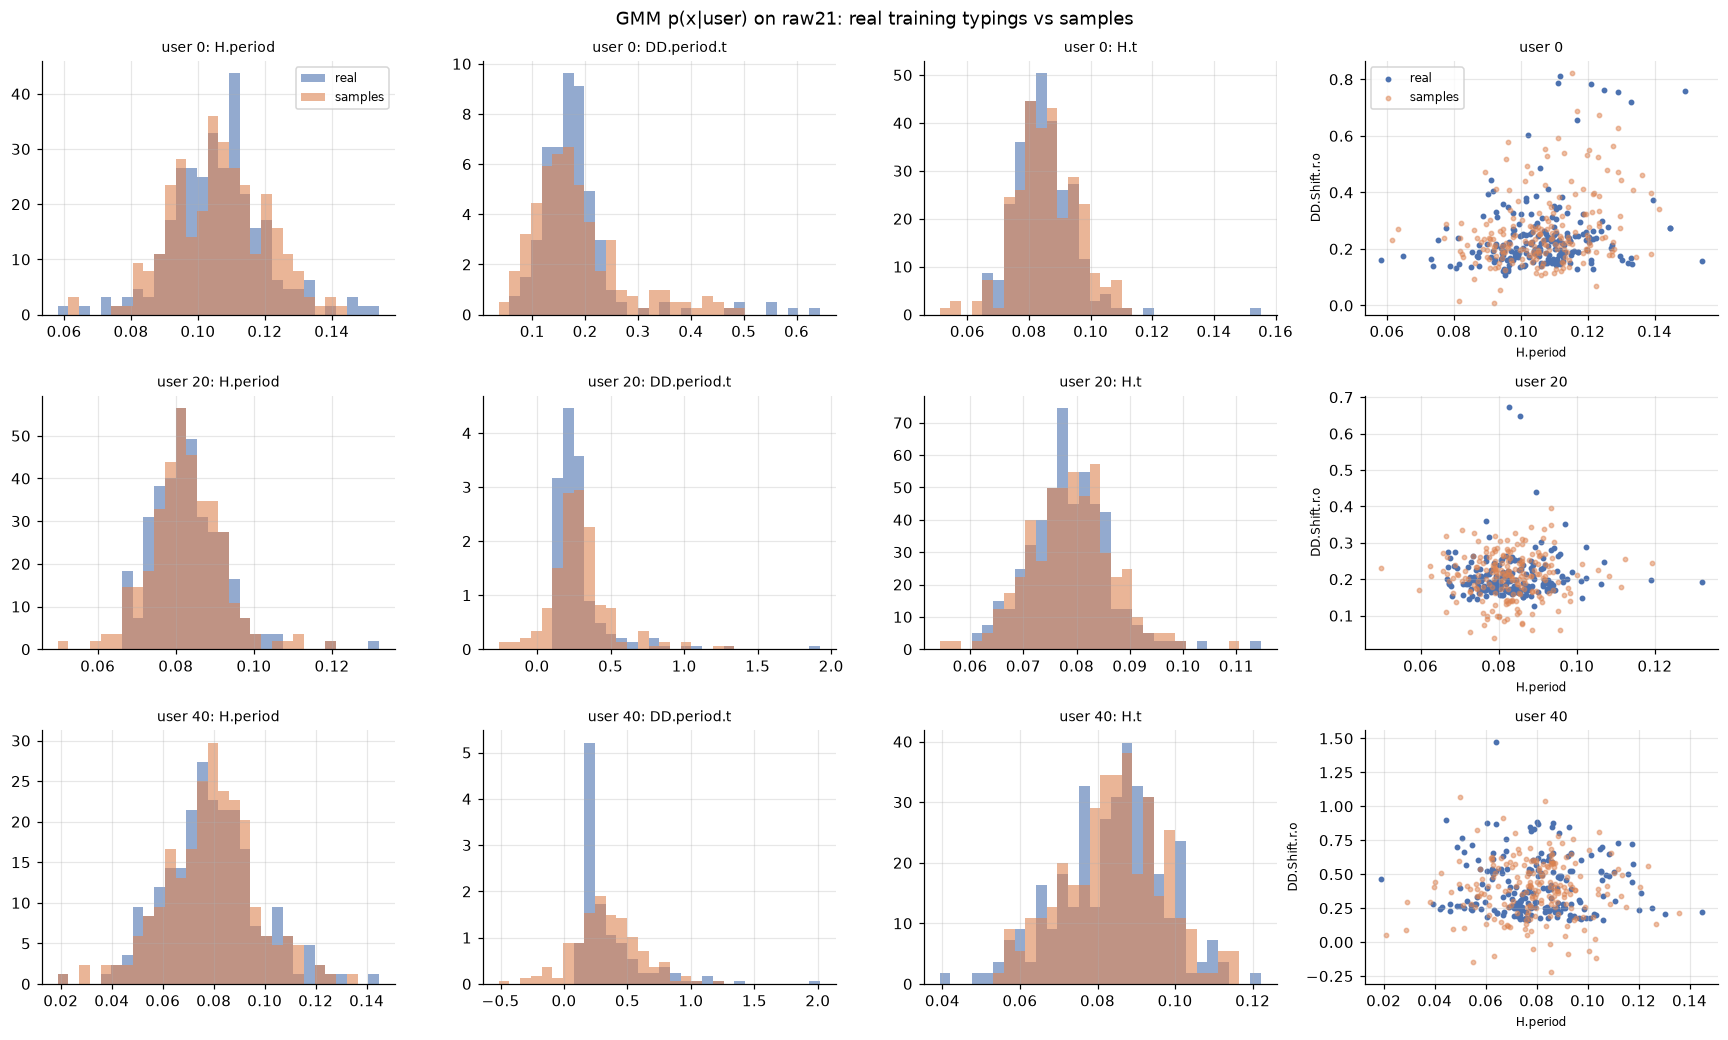

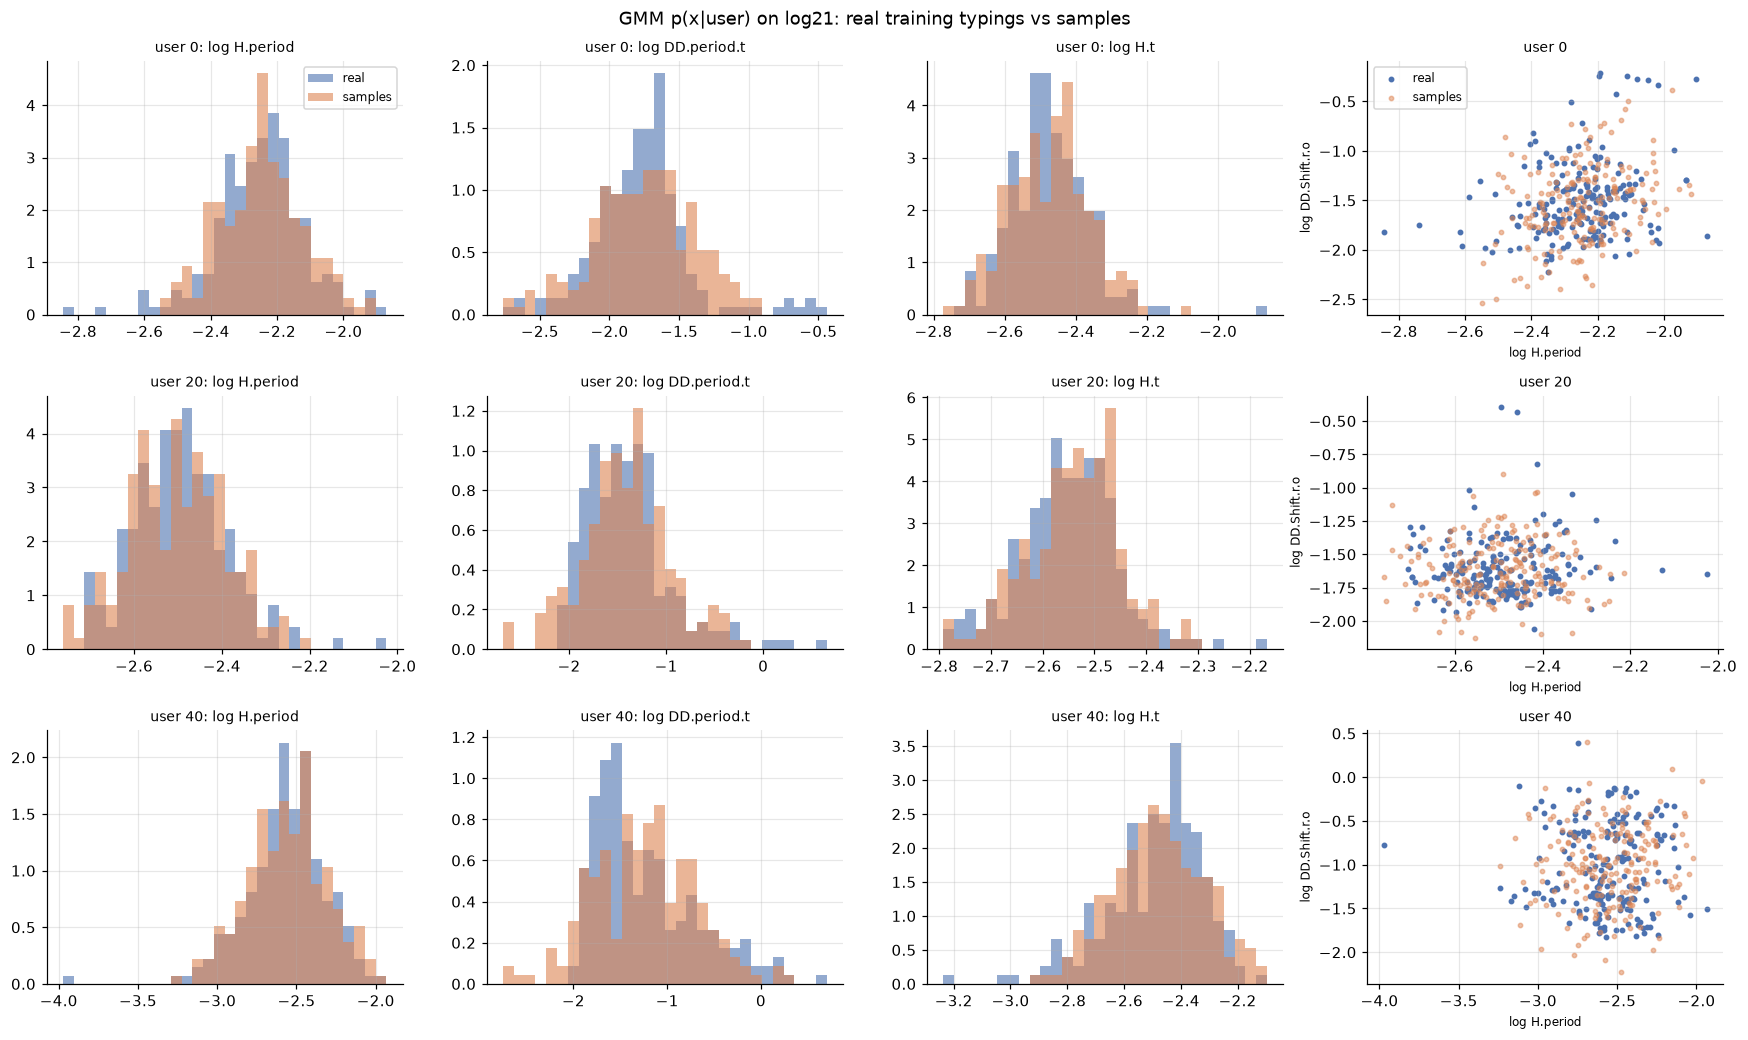

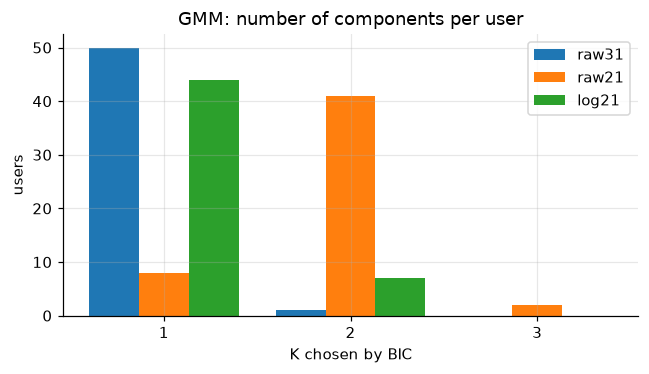

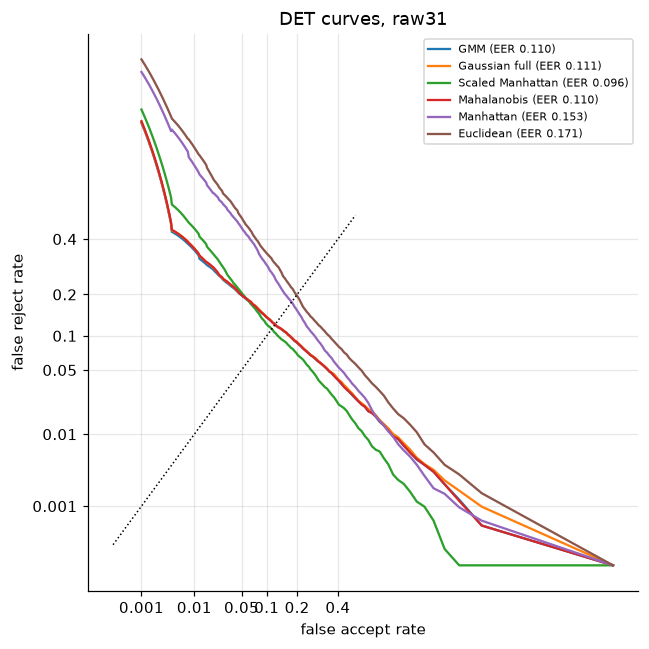

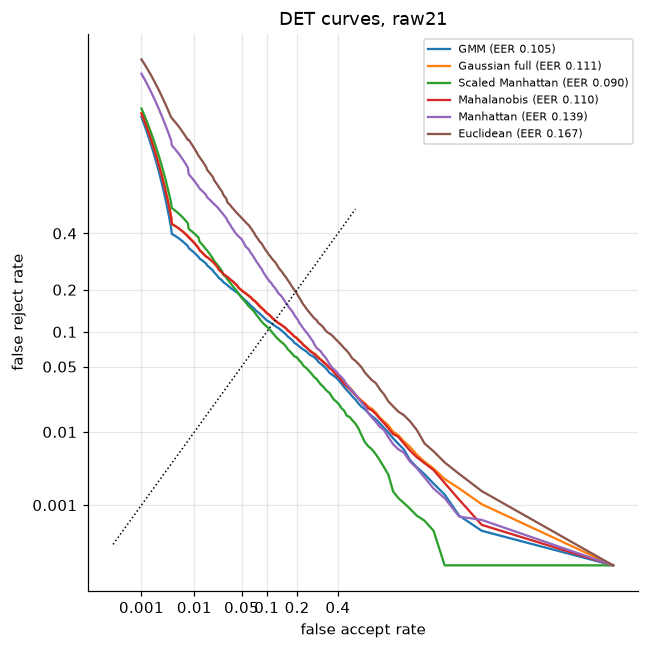

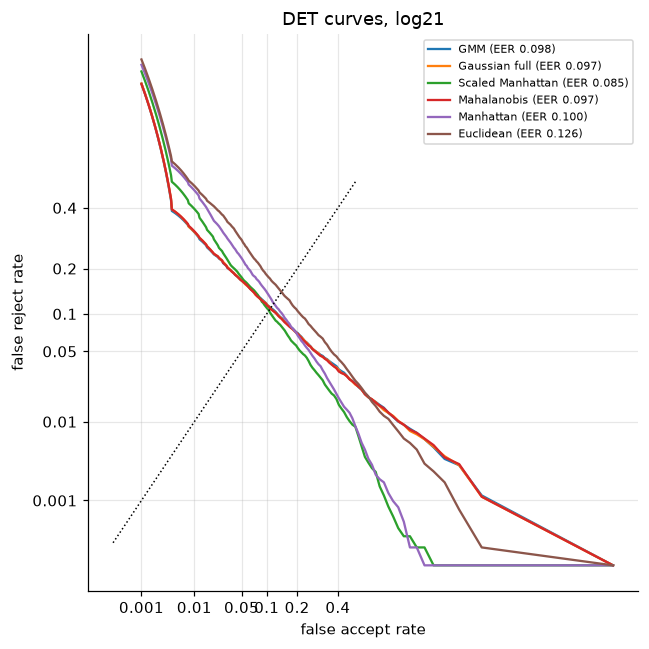

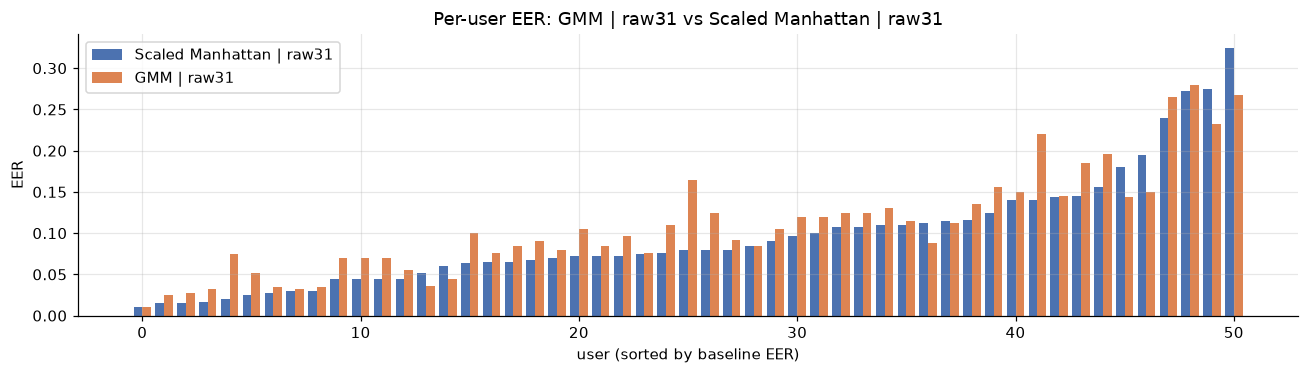

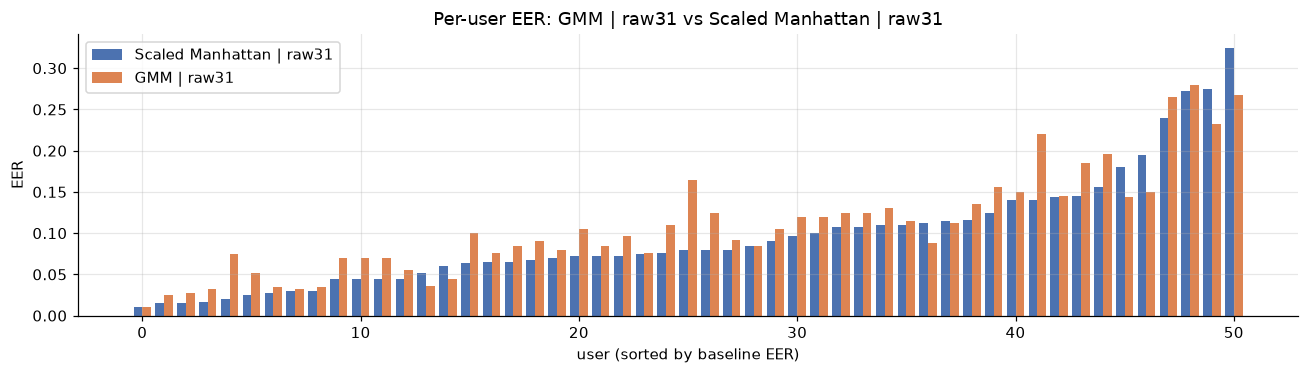

In [8]:
run_fig = start_run("bench_figures", {"model": "GMM vs detectors", "features": list(FEATURE_SETS),
                                      "protocol": "CMU benchmark", "split_short": "test", "n_train": 200,
                                      "sampling": "first", "seed": SEED})
for fs in ("raw21", "log21"):
    X_fs, names_fs = FEATS[fs]
    run_fig.add_figure(P.user_samples(X_fs, RESULTS[("GMM", fs)].models, names_fs, users=[0, 20, 40],
                                      title=f"GMM p(x|user) on {fs}: real training typings vs samples"),
                       f"gmm_samples_{fs}", report=fs == "log21")
run_fig.add_figure(P.k_distribution({fs: RESULTS[("GMM", fs)].per_user["k"] for fs in FEATURE_SETS}),
                   "gmm_k_distribution", report=True)
for fs in FEATURE_SETS:
    det = {n: RESULTS[(n, fs)] for n in ("GMM", "Gaussian full", "Scaled Manhattan", "Mahalanobis", "Manhattan", "Euclidean")}
    run_fig.add_figure(P.det_curves(det, f"DET curves, {fs}"), f"det_{fs}", report=fs == "raw31")
run_fig.add_figure(P.per_user_bars(RESULTS[("GMM", "raw31")].eers, RESULTS[("Scaled Manhattan", "raw31")].eers,
                                   "GMM | raw31", "Scaled Manhattan | raw31"), "per_user_gmm_vs_scaled_manhattan")

## 8. Evaluation

### 8a. The benchmark table

The 14 published detectors with our GMM (and the single-Gaussian control) added, all on the
benchmark's own 31 raw features. `reproduced_here` shows our re-run of the four distance detectors.
Matching the published numbers confirms that our protocol and EER computation are the same as the benchmark's.

[run] outputs\table_benchmark001_20261126-101404


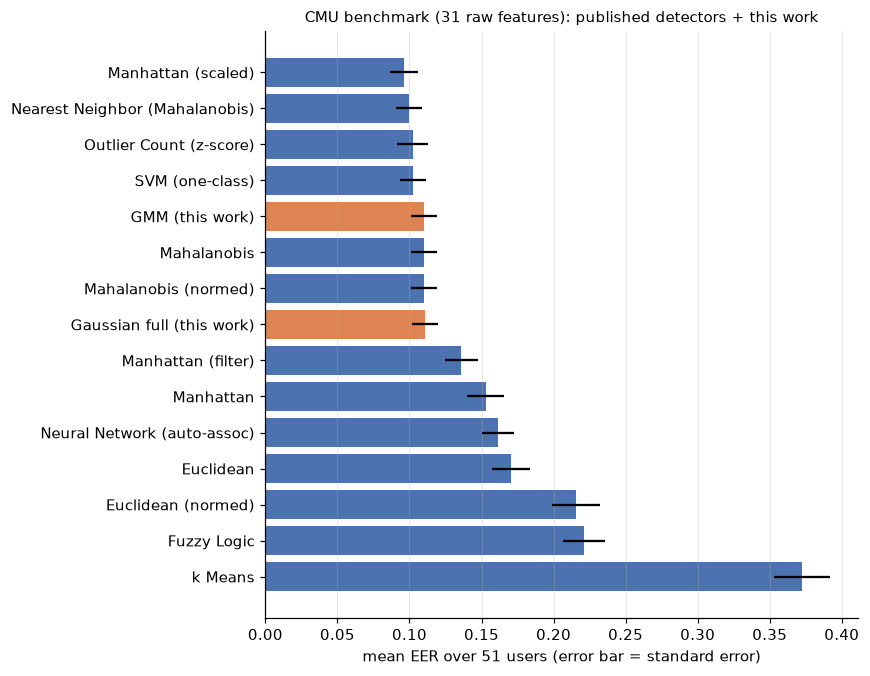

,rank,detector,eer,sd,source,reproduced_here
0,1,Manhattan (scaled),0.0962,0.0694,published,0.0962
1,2,Nearest Neighbor (Mahalanobis),0.0996,0.0642,published,NaN
2,3,Outlier Count (z-score),0.1022,0.0767,published,NaN
3,4,SVM (one-class),0.1025,0.0650,published,NaN
4,5,GMM (this work),0.1098,0.0643,this work,NaN
5,6,Mahalanobis,0.1101,0.0645,published,0.1101
6,7,Mahalanobis (normed),0.1101,0.0645,published,NaN
7,8,Gaussian full (this work),0.1106,0.0648,this work,NaN
8,9,Manhattan (filter),0.1360,0.0828,published,NaN
9,10,Manhattan,0.1529,0.0925,published,0.1529


In [9]:
raw31_new = {"GMM (this work)": RESULTS[("GMM", "raw31")], "Gaussian full (this work)": RESULTS[("Gaussian full", "raw31")]}
bench = E.benchmark_table(raw31_new, reproduced={n: RESULTS[(n, "raw31")] for n in DETECTORS})
run_bench = start_run("table_benchmark", {"model": "GMM vs published detectors", "features": "raw31",
                                          "protocol": "CMU benchmark", "split_short": "test", "n_train": 200,
                                          "sampling": "first", "seed": SEED,
                                          "published_source": "https://roymaxion.github.io/projects/keystroke-benchmark/benchmark-data-set.html"})
run_bench.add_figure(P.benchmark_bars(bench), "benchmark_table", report=True)
gmm_rank = int(bench.loc[bench.detector == "GMM (this work)", "rank"].iloc[0])
run_bench.set_results(tables={"benchmark_table": bench},
                      metrics={**RESULTS[("GMM", "raw31")].summary(), "gmm_rank_among_16": gmm_rank},
                      index={"model": "GMM (raw31) vs benchmark", "features": "raw31"})
bench

### 8b. Paired comparisons on each feature set

The published numbers only give a mean and SD. Because we have **per-subject** EERs for every model,
we can compare models on the same 51 subjects:
* `diff_vs_base` = mean of (model − Scaled Manhattan), so negative means the model is better;
* `diff_ci95` = bootstrap 95% CI of that difference;
* `wilcoxon_p` = Wilcoxon signed-rank test;
* `better_worse` = number of subjects where the model is better / worse.

`test_ll_median` is the median, over subjects, of the mean log-likelihood of the genuine test typings.
Values in the millions would mean a collapsed (degenerate) fit.

In [10]:
ORDER = ["GMM", "Gaussian full", *DETECTORS]
PAIRED = {fs: E.paired_table({n: RESULTS[(n, fs)] for n in ORDER}, "Scaled Manhattan") for fs in FEATURE_SETS}
for fs, t in PAIRED.items():
    display(Markdown(f"**{fs}**: {FEATURE_SETS[fs]}"))
    display(t)

**raw31**: 31 raw timings: the benchmark's features

,model,mean_eer,sd,ci95,test_ll_median,test_ll_min,diff_vs_base,diff_ci95,wilcoxon_p,better_worse
0,Scaled Manhattan,0.0962,0.0694,"[0.0778, 0.1161]",NaN,NaN,NaN,NaN,NaN,NaN
1,GMM,0.1098,0.0643,"[0.0922, 0.1279]",65.6306,36.0909,0.0136,"[+0.0064, +0.0206]",2.7651e-04,8/41
2,Mahalanobis,0.1101,0.0645,"[0.0924, 0.1281]",NaN,NaN,0.0139,"[+0.0067, +0.0209]",2.2350e-04,8/41
3,Gaussian full,0.1106,0.0648,"[0.0930, 0.1286]",80.8393,47.8711,0.0144,"[+0.0074, +0.0213]",1.5518e-04,9/42
4,Manhattan,0.1529,0.0925,"[0.1283, 0.1793]",NaN,NaN,0.0567,"[+0.0401, +0.0781]",6.3800e-09,4/46
5,Euclidean,0.1706,0.0952,"[0.1454, 0.1981]",NaN,NaN,0.0744,"[+0.0525, +0.1010]",2.3765e-08,5/46


**raw21**: 11 H + 10 DD raw timings: same information, redundant UD removed

,model,mean_eer,sd,ci95,test_ll_median,test_ll_min,diff_vs_base,diff_ci95,wilcoxon_p,better_worse
0,Scaled Manhattan,0.0905,0.0708,"[0.0717, 0.1107]",NaN,NaN,NaN,NaN,NaN,NaN
1,GMM,0.1045,0.0632,"[0.0874, 0.1224]",40.0483,25.9869,0.0141,"[+0.0068, +0.0213]",5.0068e-04,13/37
2,Mahalanobis,0.1101,0.0645,"[0.0924, 0.1281]",NaN,NaN,0.0196,"[+0.0127, +0.0262]",3.5645e-06,8/43
3,Gaussian full,0.1110,0.0647,"[0.0934, 0.1292]",38.6855,23.3842,0.0205,"[+0.0136, +0.0272]",2.3084e-06,8/43
4,Manhattan,0.1386,0.0833,"[0.1165, 0.1625]",NaN,NaN,0.0481,"[+0.0321, +0.0681]",1.8137e-07,5/44
5,Euclidean,0.1674,0.0930,"[0.1429, 0.1941]",NaN,NaN,0.0769,"[+0.0534, +0.1047]",4.8833e-08,5/46


**log21**: log of the 11 H + 10 DD timings

,model,mean_eer,sd,ci95,test_ll_median,test_ll_min,diff_vs_base,diff_ci95,wilcoxon_p,better_worse
0,Scaled Manhattan,0.0855,0.0697,"[0.0669, 0.1048]",NaN,NaN,NaN,NaN,NaN,NaN
1,Gaussian full,0.0974,0.0550,"[0.0825, 0.1126]",-2.6304,-11.4955,0.0120,"[+0.0038, +0.0195]",3.0781e-03,10/39
2,Mahalanobis,0.0974,0.0551,"[0.0825, 0.1127]",NaN,NaN,0.0120,"[+0.0036, +0.0196]",2.7482e-03,10/39
3,GMM,0.0978,0.0571,"[0.0822, 0.1136]",-2.9547,-16.1215,0.0123,"[+0.0039, +0.0200]",1.3959e-03,10/40
4,Manhattan,0.0998,0.0714,"[0.0808, 0.1196]",NaN,NaN,0.0144,"[+0.0107, +0.0181]",1.5032e-08,6/43
5,Euclidean,0.1259,0.0657,"[0.1083, 0.1439]",NaN,NaN,0.0405,"[+0.0324, +0.0484]",7.3083e-09,6/45


### 8c. Does the mixture help? GMM vs a single Gaussian

When BIC picks $K=1$ for a subject, the GMM *is* a single Gaussian. This paired test asks whether
allowing $K>1$ changes the EER, compared with the tuned single full Gaussian on the same features.

In [11]:
mix = []
for fs in FEATURE_SETS:
    g, f = RESULTS[("GMM", fs)], RESULTS[("Gaussian full", fs)]
    p = U.paired_test(g.eers, f.eers)       # diff = GMM - single Gaussian
    k = g.per_user["k"]
    mix.append({"features": fs, "gmm_eer": g.eers.mean(), "single_gaussian_eer": f.eers.mean(),
                "diff": p["mean_diff"], "diff_ci95": f"[{p['diff_ci95_low']:+.4f}, {p['diff_ci95_high']:+.4f}]",
                "wilcoxon_p": p["wilcoxon_p"], "users_K1/K2/K3": "/".join(str(int((k == j).sum())) for j in (1, 2, 3)),
                "gmm_test_ll_median": g.summary()["test_ll_median"], "single_test_ll_median": f.summary()["test_ll_median"]})
mixture_table = pd.DataFrame(mix)
mixture_table

,features,gmm_eer,single_gaussian_eer,diff,diff_ci95,wilcoxon_p,users_K1/K2/K3,gmm_test_ll_median,single_test_ll_median
0,raw31,0.1098,0.1106,-0.0008,"[-0.0017, +0.0001]",0.1152,50/1/0,65.6306,80.8393
1,raw21,0.1045,0.1110,-0.0065,"[-0.0101, -0.0030]",0.0016,8/41/2,40.0483,38.6855
2,log21,0.0978,0.0974,0.0004,"[-0.0013, +0.0021]",0.6258,44/7/0,-2.9547,-2.6304


### 8d. GMM diagnostics: what do the extra components capture?

For subjects with $K \ge 2$, we assign each training typing to its most likely component and
cross-tabulate components against the four training sessions:
* `ari_vs_session`: adjusted Rand index between components and sessions (0 = unrelated, 1 = identical);
* `purity_by_session`: share of typings in their component's majority session (0.25 = no alignment).

If components tracked sessions, the GMM would be modelling day-to-day drift in typing rhythm.

[run] outputs\bench_gmm_diagnostics001_20261126-101404
raw31: 1 subjects with K>=2 | mean ARI vs session 0.011 | mean purity 0.315
raw21: 43 subjects with K>=2 | mean ARI vs session 0.037 | mean purity 0.337


log21: 7 subjects with K>=2 | mean ARI vs session 0.026 | mean purity 0.327


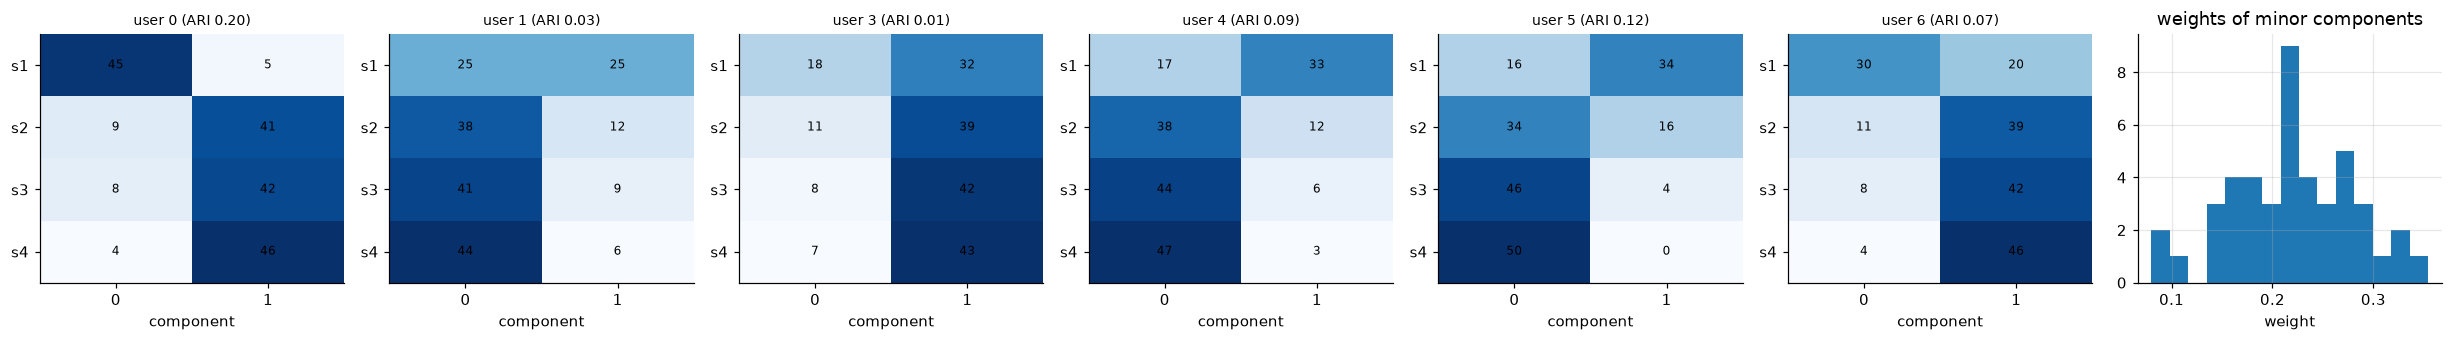

,user,k,weights,ari_vs_session,ari_vs_early_late,purity_by_session
0,0,2,"[0.671, 0.329]",0.202,0.173,0.455
1,1,2,"[0.743, 0.257]",0.033,0.045,0.345
2,3,2,"[0.782, 0.218]",0.008,0.016,0.305
3,4,2,"[0.727, 0.273]",0.094,0.126,0.400
4,5,2,"[0.733, 0.267]",0.122,0.208,0.420
5,6,2,"[0.734, 0.266]",0.067,0.081,0.380
6,7,2,"[0.713, 0.287]",0.168,0.218,0.440
7,8,2,"[0.646, 0.354]",0.076,0.049,0.385
8,9,2,"[0.78, 0.22]",0.046,0.054,0.370
9,10,2,"[0.771, 0.229]",0.024,0.037,0.335


In [12]:
run_diag = start_run("bench_gmm_diagnostics", {"model": "GMM", "features": list(FEATURE_SETS), "protocol": "CMU benchmark",
                                               "split_short": "train", "n_train": 200, "sampling": "first", "seed": SEED})
DIAG = {}
with run_diag.capture():
    for fs in FEATURE_SETS:
        gd, ct = E.gmm_session_alignment(FEATS[fs][0], RESULTS[("GMM", fs)].models)
        DIAG[fs] = (gd, ct)
        if len(gd):
            print(f"{fs}: {len(gd)} subjects with K>=2 | mean ARI vs session {gd.ari_vs_session.mean():.3f} "
                  f"| mean purity {gd.purity_by_session.mean():.3f}")
best_fs = max(DIAG, key=lambda f: len(DIAG[f][0]))      # the feature set with the most multi-component subjects
gd, ct = DIAG[best_fs]
if len(gd):
    run_diag.add_figure(P.gmm_components_vs_sessions(ct, gd, RESULTS[("GMM", best_fs)].models),
                        f"gmm_components_vs_sessions_{best_fs}", report=True)
run_diag.set_results(tables={f"alignment_{fs}": d[0] for fs, d in DIAG.items() if len(d[0])},
                     metrics={fs: {"n_multi": len(d[0]),
                                   "mean_ari_vs_session": float(d[0].ari_vs_session.mean()) if len(d[0]) else None}
                              for fs, d in DIAG.items()})
gd.round(3)

### 8e. Summary

All tables are also written to the run folders by the save cell below.

In [13]:
run_sum = start_run("table_gmm_summary", {"model": "GMM vs detectors (all feature sets)", "features": list(FEATURE_SETS),
                                          "protocol": "CMU benchmark", "split_short": "test", "n_train": 200,
                                          "sampling": "first", "seed": SEED})
summary = pd.DataFrame({fs: {n: RESULTS[(n, fs)].eers.mean() for n in ORDER} for fs in FEATURE_SETS})
with run_sum.capture():
    print(f"GMM rank on the benchmark (raw31): {gmm_rank} of {len(bench)}")
    print(f"total time {(time.time() - T0) / 60:.1f} min")
run_sum.set_results(tables={"eer_by_model_and_features": summary.reset_index().rename(columns={"index": "model"}),
                            **{f"paired_{fs}": t for fs, t in PAIRED.items()}, "gmm_vs_single_gaussian": mixture_table},
                    metrics={"mean_eer": float(RESULTS[("GMM", "raw31")].eers.mean())},
                    index={"model": "summary (GMM raw31 EER)"})
display(Markdown("**Mean EER** by model (rows) and feature set (columns)"))
summary.round(4)

[run] outputs\table_gmm_summary001_20261126-101405
GMM rank on the benchmark (raw31): 5 of 16
total time 0.4 min


**Mean EER** by model (rows) and feature set (columns)

,raw31,raw21,log21
GMM,0.1098,0.1045,0.0978
Gaussian full,0.1106,0.1110,0.0974
Euclidean,0.1706,0.1674,0.1259
Manhattan,0.1529,0.1386,0.0998
Mahalanobis,0.1101,0.1101,0.0974
Scaled Manhattan,0.0962,0.0905,0.0855


### Conclusions

*(Numbers from the run of this notebook committed with the repo. Every step is seeded, so a re-run reproduces them.)*

1. **On the benchmark's own terms (raw31), the GMM ranks 5th of 16, with a mean EER of 10.98% (SD 6.43%).**
   That is better than Mahalanobis (11.01%) and the other 10 detectors below it, but behind
   Scaled Manhattan (9.62%), Nearest Neighbor (Mahalanobis) (9.96%), Outlier Count (10.22%) and the
   one-class SVM (10.25%). Paired over the 51 subjects, it is significantly worse than Scaled Manhattan:
   +1.36 points, CI [+0.64, +2.06], Wilcoxon p < 0.001, worse for 41 subjects.
2. **On raw31 the GMM is effectively a single Gaussian.** BIC picks $K=1$ for 50 of 51 subjects,
   because in 31 dimensions each extra component costs about 500 parameters for 200 typings. Its EER is
   therefore that of a regularised Mahalanobis detector.
3. **The mixture helps only when the data are skewed.** On raw21, which has the same information as raw31,
   BIC picks $K \ge 2$ for 43 subjects (41 with $K=2$, 2 with $K=3$). The mixture then beats the single
   Gaussian by 0.65 points (CI [−1.01, −0.30], p = 0.002). For all 43 of those subjects, the minor
   component (about 25% of the weight) is both slower (larger mean timings) and wider (larger covariance)
   than the main one: it is a "slow tail". The components do *not* follow sessions (mean ARI 0.04).
   In other words, the extra component models the right-skew of raw timings, not day-to-day drift.
4. **A log transform does the same job more simply.** On log21 the skew is gone (mean skewness 6.8 → 0.1),
   BIC returns to $K=1$ for 44 subjects, and GMM ≈ single Gaussian (9.78% vs 9.74%, p = 0.63).
   The log transform improves *every* detector, though, so the gain is not specific to the GMM.
5. **No feature set lets the GMM beat Scaled Manhattan.** The gap is 1.2-1.4 points everywhere, and Scaled
   Manhattan improves with the log transform too (9.62% → 8.55%). Its per-feature robust scaling beats
   full-covariance densities when each subject has only 200 typings.

Caveats: the GMM's best `reg_covar` on raw31 and raw21 is the largest value in the grid (0.03), so a wider
grid might help slightly. The test log-likelihoods are finite and sane (median 66 on raw31, 40 on raw21,
−3 on log21). They are not comparable across feature sets, because the densities live in different spaces.

## 9. Save everything

Writes, for every run created above: `best_model/` (chosen hyperparameters, grid results and
per-subject model parameters), `visualizations/`, `metrics.json`, `per_user.csv`, `scores.npz` and
`log.txt`. It also appends each run to `outputs/runs_index.csv`, and copies the report figures to
`outputs/report_figures/`.

In [14]:
saved = save_all()
print(f"saved {len(saved)} runs to {saver.out}")
saved

saved 23 runs to C:\classProjects\keystroke-gmm\CAP5610-Keystroke-Analysis\outputs


,run,figures,mean_eer
0,bench_data_overview001_20261126-101340,2,NaN
1,bench_GMM_raw31001_20261126-101340,0,0.1098
2,bench_Gaussian_full_raw31001_20261126-101345,0,0.1106
3,bench_GMM_raw21001_20261126-101345,0,0.1045
4,bench_Gaussian_full_raw21001_20261126-101351,0,0.1110
5,bench_GMM_log21001_20261126-101351,0,0.0978
6,bench_Gaussian_full_log21001_20261126-101356,0,0.0974
7,bench_Euclidean_raw31001_20261126-101401,0,0.1706
8,bench_Manhattan_raw31001_20261126-101401,0,0.1529
9,bench_Mahalanobis_raw31001_20261126-101401,0,0.1101
